# Alzheimer MRI Classification - Improved Transfer Learning Pipeline

This notebook replaces the original flat DIET classifier with a stronger transfer-learning workflow built around a pretrained `EfficientNet-B0` backbone.


## What Changed

- pretrained CNN backbone instead of flattening raw pixels
- train/validation split with stratification
- stronger MRI-safe augmentation plus random erasing
- weighted sampler and softer class weights for imbalance
- head warmup, AdamW, gradient clipping, LR scheduling, and early stopping
- patient-level test evaluation by averaging repeated slices inferred from filenames
- stronger evaluation with balanced accuracy, macro F1, confusion matrix, and ROC-AUC

In [1]:
import importlib

import EfficientNet_B0_alzheimer_pipeline as pipeline

pipeline = importlib.reload(pipeline)

TrainingConfig = pipeline.TrainingConfig
plot_confusion_matrix_from_results = pipeline.plot_confusion_matrix_from_results
plot_dataset_distribution = pipeline.plot_dataset_distribution
plot_roc_curves_from_results = pipeline.plot_roc_curves_from_results
plot_training_curves = pipeline.plot_training_curves
print_audit_summary = pipeline.print_audit_summary
print_classification_report = pipeline.print_classification_report
print_test_metrics = pipeline.print_test_metrics
refresh_test_evaluation = pipeline.refresh_test_evaluation
run_experiment = pipeline.run_experiment

C:\Users\akpan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
config = TrainingConfig(
    img_size=224,
    batch_size=32,
    epochs=10,
    val_size=0.15,
    backbone_lr=3e-5,
    head_lr=1e-4,
    weight_decay=5e-4,
    label_smoothing=0.08,
    dropout=0.5,
    random_erasing_prob=0.15,
    use_weighted_sampler=True,
    sampler_power=0.5,
    class_weight_power=0.5,
    freeze_backbone_epochs=2,
    gradient_clip_norm=1.0,
    early_stopping_patience=5,
    reduce_lr_patience=2,
    split_by_hash_groups=True,
    deduplicate_train=True,
    audit_dataset=True,
    seed=42,
)

config

TrainingConfig(train_dir='Dataset/Training Set', test_dir='Dataset/Testing Set', img_size=224, batch_size=32, epochs=10, val_size=0.15, backbone_lr=3e-05, head_lr=0.0001, weight_decay=0.0005, label_smoothing=0.08, dropout=0.5, random_erasing_prob=0.15, use_weighted_sampler=True, sampler_power=0.5, class_weight_power=0.5, freeze_backbone_epochs=2, gradient_clip_norm=1.0, early_stopping_patience=5, reduce_lr_patience=2, split_by_hash_groups=True, deduplicate_train=True, audit_dataset=True, seed=42, num_workers=0)

## Train The Model

Run the next cell to prepare the data, train the model, restore the best checkpoint, and evaluate on the test set.


In [3]:
results = run_experiment(config)
test_results = results["test_results"]


Using device: cuda
Config:
  train_dir: Dataset/Training Set
  test_dir: Dataset/Testing Set
  img_size: 224
  batch_size: 32
  epochs: 10
  val_size: 0.15
  backbone_lr: 3e-05
  head_lr: 0.0001
  weight_decay: 0.0005
  label_smoothing: 0.08
  dropout: 0.5
  random_erasing_prob: 0.15
  use_weighted_sampler: True
  sampler_power: 0.5
  class_weight_power: 0.5
  freeze_backbone_epochs: 2
  gradient_clip_norm: 1.0
  early_stopping_patience: 5
  reduce_lr_patience: 2
  split_by_hash_groups: True
  deduplicate_train: True
  audit_dataset: True
  seed: 42
  num_workers: 0


Class distribution
------------------------------------------------------------
Class                   Train      Val     Test
------------------------------------------------------------
MildDemented             7506     1324      896
ModerateDemented         5227      922       64
NonDemented              8146     1438     3200
VeryMildDemented         7602     1341     2240
------------------------------------------------------------
Dataset audit
------------------------------------------------------------
Train duplicate groups: 195
Redundant duplicate train files: 462
Cross-class duplicate groups: 0
Exact train/val hash overlap after split: 0
Exact train/test hash overlap: 0
Train samples used after split: 28481
Validation samples used after split: 5025
------------------------------------------------------------
Test patient-group audit (inferred from filename)
------------------------------------------------------------
Class                  Images   Patients   Repeat   Mean/

Epoch 01/10 | train_loss=1.3373 | train_acc=0.3500 | val_loss=1.2721 | val_acc=0.4406 | val_macro_f1=0.4304 | val_macro_auc=0.7133


Epoch 02/10 | train_loss=1.2616 | train_acc=0.4313 | val_loss=1.2119 | val_acc=0.4951 | val_macro_f1=0.4815 | val_macro_auc=0.7516
Backbone unfrozen. Fine-tuning the full network.


Epoch 03/10 | train_loss=0.9529 | train_acc=0.6137 | val_loss=0.7993 | val_acc=0.7228 | val_macro_f1=0.7348 | val_macro_auc=0.9114


...

Epoch 06/10 | train_loss=0.5663 | train_acc=0.8602 | val_loss=0.4983 | val_acc=0.9023 | val_macro_f1=0.9116 | val_macro_auc=0.9872


Epoch 07/10 | train_loss=0.5017 | train_acc=0.9001 | val_loss=0.4333 | val_acc=0.9439 | val_macro_f1=0.9490 | val_macro_auc=0.9951


Epoch 08/10 | train_loss=0.4600 | train_acc=0.9248 | val_loss=0.3959 | val_acc=0.9646 | val_macro_f1=0.9678 | val_macro_auc=0.9981


Epoch 09/10 | train_loss=0.4243 | train_acc=0.9453 | val_loss=0.3661 | val_acc=0.9799 | val_macro_f1=0.9817 | val_macro_auc=0.9993


Epoch 10/10 | train_loss=0.4008 | train_acc=0.9568 | val_loss=0.3449 | val_acc=0.9877 | val_macro_f1=0.9888 | val_macro_auc=0.9997
Best checkpoint restored from epoch 10.


## Dataset Distribution


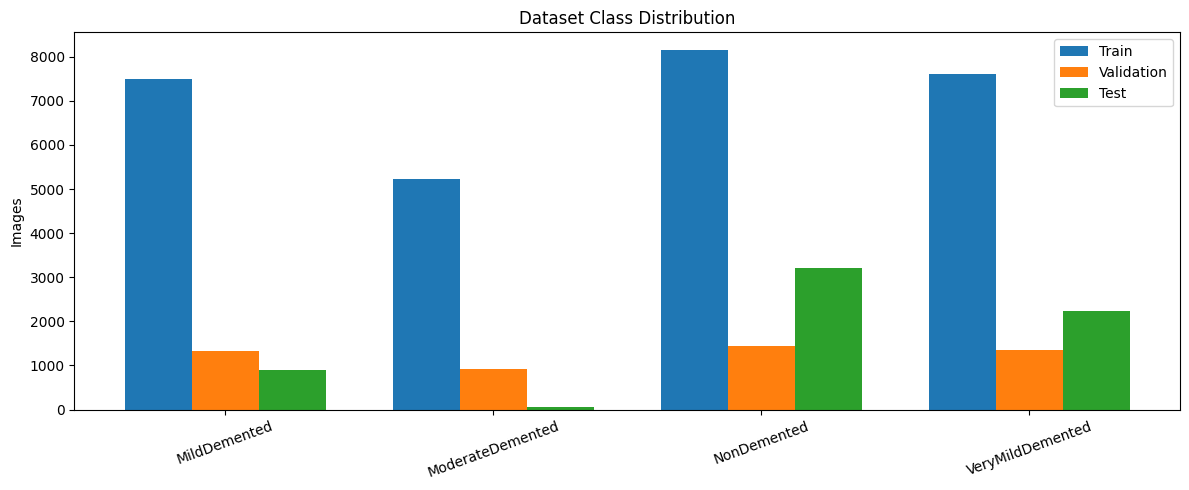

In [4]:
plot_dataset_distribution(
    results["class_names"],
    results["train_counts"],
    results["val_counts"],
    results["test_counts"],
)


## Training Curves


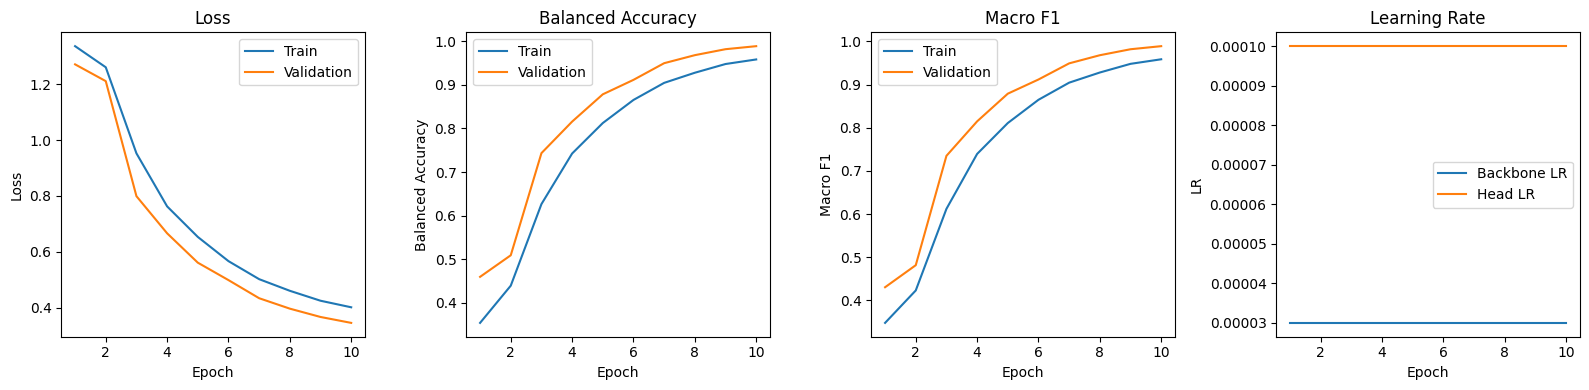

In [5]:
plot_training_curves(results["history"])


## Test Metrics


In [6]:
print_test_metrics(test_results)
print_classification_report(test_results)


Image-level test metrics
Test loss: 0.1028
Accuracy: 0.9831
Balanced accuracy: 0.9911
Macro F1: 0.9885
Weighted F1: 0.9831
Macro precision: 0.9863
Macro recall: 0.9911
Macro ROC-AUC (OvR): 0.9996

Patient-level test metrics (slice probabilities averaged per inferred patient)
Patients evaluated: 5148
Multi-slice patients: 27
Max slices for one patient: 100
Inconsistent label groups: 0
Accuracy: 0.9868
Balanced accuracy: 0.9931
Macro F1: 0.9911
Weighted F1: 0.9868
Macro precision: 0.9892
Macro recall: 0.9931
Macro ROC-AUC (OvR): 0.9997
Image-level classification report
                  precision    recall  f1-score   support

    MildDemented       0.98      1.00      0.99       896
ModerateDemented       1.00      1.00      1.00        64
     NonDemented       1.00      0.97      0.98      3200
VeryMildDemented       0.96      1.00      0.98      2240

        accuracy                           0.98      6400
       macro avg       0.99      0.99      0.99      6400
    weighted avg  

## Confusion Matrices


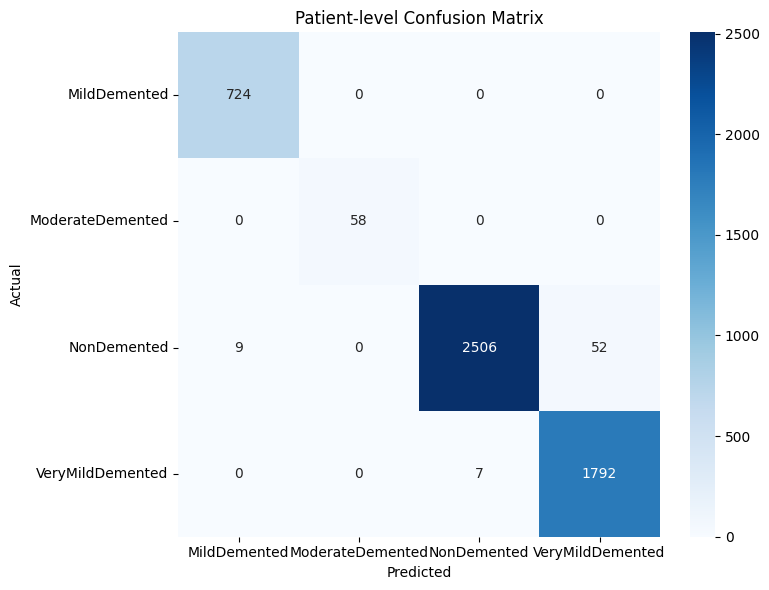

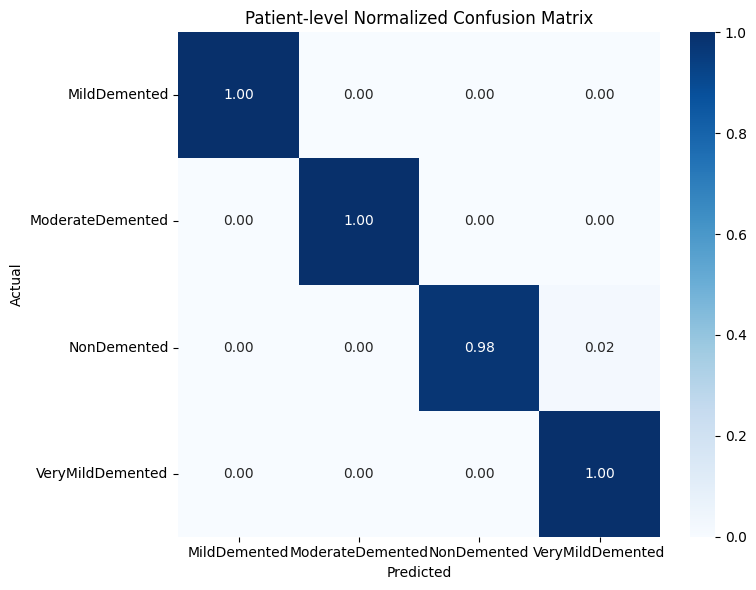

In [7]:
plot_confusion_matrix_from_results(test_results, results["class_names"], normalize=False)
plot_confusion_matrix_from_results(test_results, results["class_names"], normalize=True)


## ROC Curves


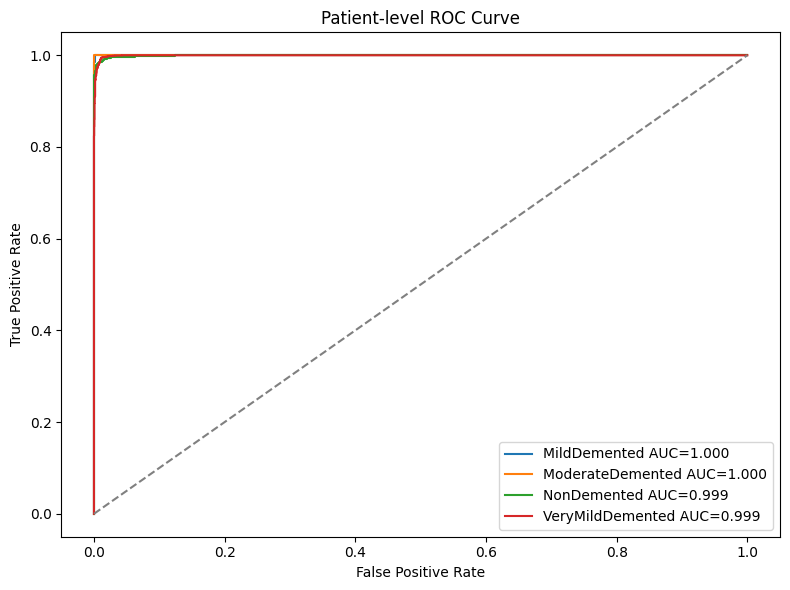

{'per_class_auc': {0: 0.9999285039912881,
  1: 1.0,
  2: 0.9993804172923496,
  3: 0.9994754227116986},
 'macro_auc': 0.999696085998834,
 'level': 'Patient-level'}

In [8]:
roc_summary = plot_roc_curves_from_results(test_results, results["class_names"])
roc_summary
